In [22]:
import pandas as pd

In [23]:
df=pd.read_csv("/content/covid_19_clean_complete.csv")
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [24]:
df.shape

(49068, 10)

In [25]:
df.dtypes

,0
Province/State,object
Country/Region,object
Lat,float64
Long,float64
Date,object
Confirmed,int64
Deaths,int64
Recovered,int64
Active,int64
WHO Region,object


In [26]:
df.isna().sum()

,0
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0


##There are 34404 null values in province/state out of 49068 rows


In [27]:
df=df.drop("Province/State",axis=1)
df

,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...
49063,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [28]:
gc=df.groupby("Date")["Confirmed"].sum().reset_index()
gc

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [29]:
gc["Date"]=pd.to_datetime(gc["Date"])

In [30]:
import matplotlib.pyplot as plt
import seaborn as scn


/tmp/ipython-input-724901331.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


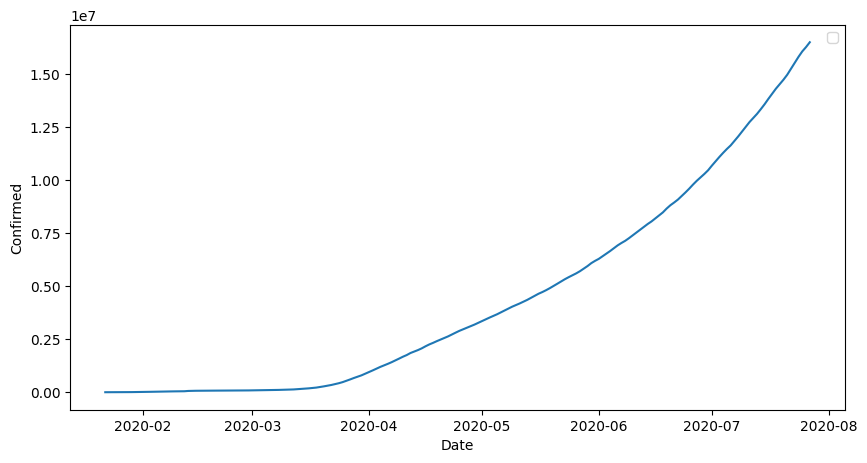

In [31]:
plt.figure(figsize=(10,5))
plt.plot(gc["Date"],gc["Confirmed"])
plt.legend()
plt.xlabel("Date")
plt.ylabel("Confirmed")
plt.show()

##In early 2020 the confirmed cases was low and end of march the confirmed cases started to climb up and in july confirmed cases climbed up to 16 million

In [32]:
from statsmodels.tsa.seasonal import seasonal_decompose

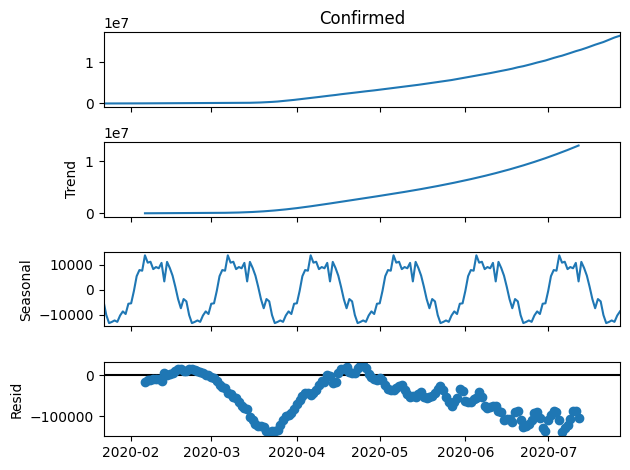

In [33]:
gc.set_index("Date",inplace=True)
dc=seasonal_decompose(gc["Confirmed"],model="additive",period=30)
dc.plot()
plt.tight_layout()
plt.show()

#The main thing driving the epidemics growth is the overall trend basically, a steady and pretty intense rise in global cases. There are some seasonal patterns, but theyre not a big deal and probably have more to do with how the data was reported than anything about the virus itself


In [34]:
train=gc["Confirmed"][:-30]
test=gc["Confirmed"][-30:]

In [35]:
from statsmodels.tsa.arima.model import ARIMA

In [36]:
model=ARIMA(train,order=(2,1,2))
fitted=model.fit()

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


In [37]:
fc=fitted.forecast(steps=30)
fc.index=test.index

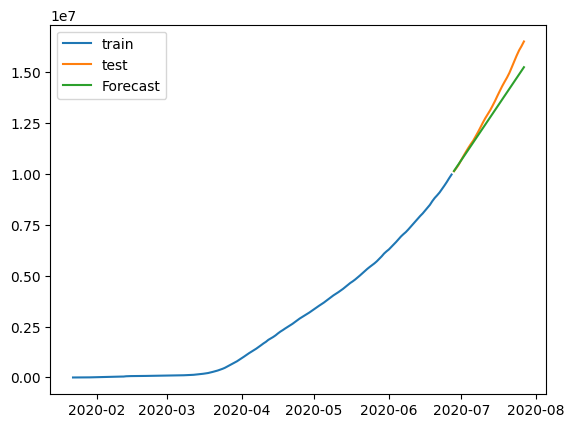

In [38]:

plt.plot(train.index,train,label="train")
plt.plot(test.index,test,label="test")
plt.plot(fc.index,fc,label="Forecast")
plt.legend()

#The ARIMA model does a solid job of fitting the past data and predicting whats coming next  and its forecasts line up pretty well with the actual test results

In [39]:
from sklearn import metrics
import numpy as np

In [40]:
print(f"RMSE={np.sqrt(metrics.mean_squared_error(test,fc))}")
print(f"MAPE={metrics.mean_absolute_percentage_error(test,fc)}")

RMSE=604525.9031382897
MAPE=0.031181068227690747


#Here very low MAPE indicates strong model performance

#CONCLUSION
* There are 34404 null values in province/state out of 49068 rows and the column doesnt affect the model so we can drop the column.

* In early 2020 the confirmed cases was low and end of march the confirmed cases started to climb up and in july confirmed cases climbed up to 16 million.

* The main thing driving the epidemics growth is the overall trend  basically, a steady and pretty intense rise in global cases. There are some seasonal patterns, but theyre not a big deal and probably have more to do with how the data was reported than anything about the virus itself.

* The ARIMA model does a solid job of fitting the past data and predicting whats coming next and its forecasts line up pretty well with the actual test results.

* Here very low MAPE indicates strong model performance.

